# Field Shift · Punto 6: qué está sembrado este año, antes del mapa del USDA

**Qué ve el productor:** en plena temporada, qué cultivo hay en el lote según el satélite, con su probabilidad. El mapa oficial del USDA (Cropland Data Layer, CDL) de un año sale recién a principios del año siguiente. Por ejemplo:

> "As of July 15, this field looks like soybeans (97% likely), from Sentinel-2 and Landsat passes. USDA's crop map for this year comes out months later."

**Cómo se hace:** un clasificador (LightGBM) aprende de los años anteriores cómo se ven el maíz y la soja desde el satélite a lo largo de la temporada. Las etiquetas son el CDL de esos años, y las imágenes son las pasadas despejadas de Landsat y Sentinel-2 (HLS) de cada píxel de 30 m. Después se le muestra lo que se vio **hasta una fecha** del año en curso y dice qué cultivo es.

**No es el modelo A ni el B del `CLAUDE.md`:** no predice rinde, clasifica el cultivo. Es el uso #6 del issue #6, el que Lucho marcó como "Alta: no da para el fin de semana".

**La vara a superar es la regla de rotación.** En estos lotes, "este año va lo contrario del año pasado" acierta casi siempre, y se sabe antes de sembrar. El satélite solo aporta si le gana a esa regla, y eso se mide por fecha de corte (pasos 6 y 7). El método que queda es un **híbrido**: la regla, salvo que el satélite esté seguro de otra cosa. Así se detectan los años en que el productor cambió el plan.

**Cómo usarla:** correr todo de arriba hacia abajo. Usa la parte `lotes/` de la entrega v1.3 (`backend/Datos/entregas/fieldshift_datos_v1.3/lotes/`): 10 lotes de demostración, 6.330 píxeles. Tarda unos 8 minutos.

## 0. Librerías

- **pandas / numpy:** tablas y cuentas.
- **lightgbm:** el clasificador, el mismo tipo de modelo que el punto 2.
- **matplotlib:** los dos gráficos.

In [1]:
import json
from datetime import datetime
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Parámetros

- `ANIOS`: años con etiqueta. El CDL de 2008 no tiene año anterior para la regla, así que se arranca en 2009.
- `ANIOS_VALIDACION`: los años en los que se prueba, de a uno. Para probar un año se entrena **solo con los años anteriores**, como pasaría en la realidad. Son 2016–2025 porque desde 2016 hay Sentinel-2.
- `CORTES`: hasta qué fecha se usan las pasadas del año que se clasifica. Cada corte suma una quincena.
- `UMBRAL_SATELITE`: en el híbrido, desde qué probabilidad el satélite le gana a la regla. Con 0,8, el satélite manda cuando da 80 % o más para un cultivo; si no, manda la regla.
- `CORTE_FRONT`: la fecha que se muestra en el ejemplo y en el resumen para el front.
- `ANIO_DEMO`: la "temporada en curso" de la demo. Es 2025 porque su CDL ya salió y sirve para comprobar.
- `INDICES`: los índices de vegetación de cada pasada. NDVI y EVI2 miden el verdor, GCVI la clorofila y NDMI el agua de las hojas.
- Solo se usan píxeles **interiores** (`interior == 1`), porque los del borde mezclan el lote con caminos y vecinos (`lotes/LEEME.md`).

In [2]:
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
SALIDA = RAIZ / "backend" / "Datos"
VERSION_ENTREGA = "todo_10estados_20261115"   # lotes/ es idéntica a la v1.3 (mismos 10 lotes)
RUTA_LOTES = RAIZ / "backend" / "Datos" / "entregas" / f"fieldshift_datos_{VERSION_ENTREGA}" / "ia_il_in_v3" / "lotes"
RUTA_CONDADOS = RAIZ / "backend" / "Datos" / "entregas" / f"fieldshift_datos_{VERSION_ENTREGA}" / "unido_10_estados" / "referencia" / "condados.csv"

ANIOS = range(2009, 2026)
ANIOS_VALIDACION = range(2016, 2026)
INDICES = ["ndvi", "evi2", "ndmi", "gcvi"]
# Quincenas desde el 1 de abril: 0 = 1–15 abr, 1 = 16–30 abr, 2 = 1–15 may, ... 11 = 16–30 sep
CORTES = {"06-01": 4, "06-15": 5, "07-01": 6, "07-15": 7, "08-01": 8, "08-15": 9}   # fecha -> quincenas que entran
NOMBRE_CORTE = {"06-01": "1 jun", "06-15": "15 jun", "07-01": "1 jul", "07-15": "15 jul", "08-01": "1 ago", "08-15": "15 ago"}
NOMBRE_CORTE_EN = {"06-01": "June 1", "06-15": "June 15", "07-01": "July 1", "07-15": "July 15", "08-01": "August 1", "08-15": "August 15"}
UMBRAL_SATELITE = 0.8
CORTE_FRONT = "07-15"
ANIO_DEMO = 2025
PARAMETROS_MODELO = dict(n_estimators=150, learning_rate=0.05, num_leaves=15, min_child_samples=50,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, verbose=-1)
CULTIVO_EN = {"maiz": "corn", "soja": "soy"}
NOMBRE_EN = {"maiz": "corn", "soja": "soybeans"}
COLOR = {"maiz": "#c98500", "soja": "#199e70"}   # los de web/src/ui/crops.ts

CLAVE = ["fips", "id_lote", "px_id"]
TIPOS = {"fips": str, "id_lote": str}
HAY_DATOS = all((RUTA_LOTES / f).exists() for f in ["pixeles.csv", "cultivo_px_anual.csv", "vegetacion_px_obs.csv"])
print(f"¿Está la parte lotes/ de la entrega {VERSION_ENTREGA}?", HAY_DATOS)
if not HAY_DATOS:
    print(f"Falta backend/Datos/entregas/fieldshift_datos_{VERSION_ENTREGA}/lotes/. La notebook queda en espera.")

¿Está la parte lotes/ de la entrega todo_20261115? True


## 2. Cargar los píxeles y su cultivo según el CDL

`cultivo_px_anual.csv` dice qué cultivo marcó el CDL en cada píxel y año. De ahí salen dos cosas:

- **La etiqueta** (`y`): 1 si es maíz y 0 si es soja. Las otras clases (pastizal, alfalfa, trigo) son unos pocos píxeles sueltos y se dejan afuera.
- **El cultivo del año anterior**, que se conoce antes de sembrar. Con él se arma la **regla de rotación** ("lo contrario del año pasado") y también entra como dato en uno de los modelos.

La verdad de cada **lote** en un año es el cultivo de la mayoría de sus píxeles.

In [3]:
if HAY_DATOS:
    pixeles = pd.read_csv(RUTA_LOTES / "pixeles.csv", dtype=TIPOS).query("interior == 1")
    cultivo = pd.read_csv(RUTA_LOTES / "cultivo_px_anual.csv", dtype=TIPOS).merge(pixeles[CLAVE], on=CLAVE)
    cultivo = cultivo.sort_values(CLAVE + ["anio"])
    cultivo["cultivo_anterior"] = cultivo.groupby(CLAVE)["cultivo"].shift(1)

    datos = cultivo[cultivo["cultivo"].isin(["maiz", "soja"]) & cultivo["anio"].isin(ANIOS)].copy()
    datos["y"] = (datos["cultivo"] == "maiz").astype(int)
    datos = datos.reset_index(drop=True)

    fuera = cultivo[~cultivo["cultivo"].isin(["maiz", "soja"]) & cultivo["anio"].isin(ANIOS)]
    print(f"{datos['id_lote'].nunique()} lotes, {len(pixeles)} píxeles interiores, {len(datos)} píxel-año con maíz o soja")
    print(f"Quedan afuera {len(fuera)} píxel-año de otras clases: {fuera['cultivo'].value_counts().to_dict()}")
    display(datos.groupby("anio")["cultivo"].value_counts().unstack().T)
else:
    print("En espera de la entrega.")

10 lotes, 5334 píxeles interiores, 90095 píxel-año con maíz o soja
Quedan afuera 583 píxel-año de otras clases: {'trigo_invierno': 349, 'pastizal': 165, 'otro': 52, 'alfalfa': 11, 'barbecho': 4, 'heno': 2}


anio,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
cultivo,,,,,,,,,,,,,,,,,
maiz,2594,3235,2597,4071,2383,3715,1861,4104,1255,4105,1220,4516,807,4518,1214,4482,1217
soja,2684,2079,2693,1244,2591,1605,3465,1221,4075,1222,4108,813,4522,811,4115,846,4107


## 3. Las pasadas del satélite, por quincena

`vegetacion_px_obs.csv` tiene cada pasada despejada de cada píxel: Landsat 5, 7, 8 y 9 desde 2000, y Sentinel-2 (HLS S30) desde 2016. Para que todos los años tengan la misma forma, las pasadas se resumen por **quincena**, de abril a septiembre, con la **mediana** de cada índice. Una quincena sin pasadas queda vacía: LightGBM sabe trabajar con huecos, así que no se inventan valores.

Los índices de Landsat y de Sentinel-2 se mezclan en la misma quincena. HLS está armonizado con Landsat, y los índices son cocientes de bandas, así que son comparables entre sensores.

In [4]:
if HAY_DATOS:
    pasadas = pd.read_csv(RUTA_LOTES / "vegetacion_px_obs.csv", dtype=TIPOS, usecols=CLAVE + ["anio", "fecha", "sensor"] + INDICES)
    pasadas = pasadas[pasadas["anio"].isin(ANIOS)].merge(pixeles[CLAVE], on=CLAVE)
    mes = pasadas["fecha"].str[5:7].astype(int)
    dia = pasadas["fecha"].str[8:10].astype(int)
    pasadas["quincena"] = (mes - 4) * 2 + (dia > 15).astype(int)
    pasadas = pasadas[pasadas["quincena"].between(0, 11)]

    por_quincena = pasadas.groupby(CLAVE + ["anio", "quincena"])[INDICES].median().unstack("quincena")
    por_quincena.columns = [f"{indice}_q{q:02d}" for indice, q in por_quincena.columns]
    datos = datos.merge(por_quincena.reset_index(), on=CLAVE + ["anio"], how="left")

    sentinel = pasadas["sensor"].str.startswith("S")
    print(f"{len(pasadas):,} pasadas de abril a septiembre: {sentinel.mean():.0%} de Sentinel-2".replace(",", "."))
    hasta_15jul = pasadas[pasadas["quincena"] < CORTES["07-15"]].groupby(CLAVE + ["anio"]).size()
    print("Pasadas por píxel hasta el 15 de julio (mediana), por año:")
    print(hasta_15jul.groupby("anio").median().astype(int).to_dict())
else:
    print("En espera de la entrega.")

1.319.936 pasadas de abril a septiembre: 64% de Sentinel-2
Pasadas por píxel hasta el 15 de julio (mediana), por año:
{2009: 2, 2010: 4, 2011: 3, 2012: 2, 2013: 3, 2014: 1, 2015: 3, 2016: 6, 2017: 6, 2018: 14, 2019: 12, 2020: 13, 2021: 12, 2022: 12, 2023: 18, 2024: 9, 2025: 13}


## 4. Cómo se ven el maíz y la soja desde el satélite

El NDVI mediano de cada quincena, separado por cultivo, con los años 2016–2025. El maíz se siembra antes y cierra el surco antes, así que **reverdece unas semanas antes** que la soja. Esa diferencia de junio y julio es lo que aprovecha el clasificador. En agosto los dos están verdes, pero la soja se mantiene verde más tiempo, y en septiembre el maíz ya se seca.

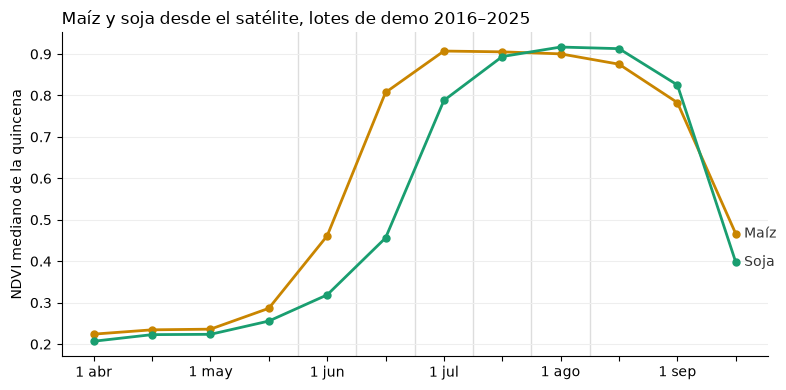

,ndvi_q00,ndvi_q01,ndvi_q02,ndvi_q03,ndvi_q04,ndvi_q05,ndvi_q06,ndvi_q07,ndvi_q08,ndvi_q09,ndvi_q10,ndvi_q11
cultivo,,,,,,,,,,,,
maiz,0.22,0.23,0.24,0.29,0.46,0.81,0.91,0.91,0.90,0.88,0.78,0.47
soja,0.21,0.22,0.22,0.26,0.32,0.46,0.79,0.89,0.92,0.91,0.83,0.40


In [5]:
if HAY_DATOS:
    columnas_ndvi = [f"ndvi_q{q:02d}" for q in range(12)]
    curva = datos[datos["anio"].isin(ANIOS_VALIDACION)].groupby("cultivo")[columnas_ndvi].median().T
    etiquetas_q = ["1 abr", "", "1 may", "", "1 jun", "", "1 jul", "", "1 ago", "", "1 sep", ""]

    fig, ax = plt.subplots(figsize=(8, 4))
    for c in ["maiz", "soja"]:
        ax.plot(range(12), curva[c].to_numpy(), color=COLOR[c], linewidth=2, marker="o", markersize=5)
        ax.annotate("Maíz" if c == "maiz" else "Soja", (11, curva[c].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", color="#333333")
    for q in CORTES.values():
        ax.axvline(q - 0.5, color="#dddddd", linewidth=1, zorder=0)
    ax.set_xticks(range(12), etiquetas_q)
    ax.set_ylabel("NDVI mediano de la quincena")
    ax.set_title("Maíz y soja desde el satélite, lotes de demo 2016–2025", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#eeeeee")
    plt.tight_layout()
    plt.show()
    display(curva.T.round(2))
else:
    print("En espera de la entrega.")

## 5. Qué sabe el modelo en cada fecha de corte

Para una fecha de corte, el modelo ve solo las quincenas anteriores a esa fecha:

- los cuatro índices de cada quincena;
- el **NDVI máximo** hasta esa fecha;
- en qué quincena el NDVI pasó 0,5 por primera vez (si pasó): mide qué tan temprano reverdeció el lote;
- cuántas quincenas tuvieron pasadas (con pocas, el modelo debería estar menos seguro).

Se comparan tres maneras de decidir:

| Método | Qué usa | Cuándo se sabe |
|---|---|---|
| **Regla de rotación** | El cultivo del año anterior: este año va el otro | Antes de sembrar |
| **Solo satélite** | Las pasadas hasta la fecha de corte | En la temporada |
| **Satélite + año anterior** | Las dos cosas juntas, en un mismo modelo | En la temporada |
| **Híbrido** | La regla, salvo que "solo satélite" dé `UMBRAL_SATELITE` o más para un cultivo | En la temporada |

El híbrido no entrena nada nuevo: combina la regla con el modelo de solo satélite. La idea es que el año anterior ya es muy buen dato, y el satélite solo tiene que avisar cuando ve otra cosa con claridad. Si el año anterior entra como una columna más del modelo, el modelo se apoya tanto en ella que no ve los cambios de plan (paso 8).

In [6]:
def armar_features(tabla, n_quincenas, con_historia):
    """Las columnas que ve el modelo con las pasadas de las primeras n_quincenas."""
    X = tabla[[f"{i}_q{q:02d}" for i in INDICES for q in range(n_quincenas)]].copy()
    ndvi = tabla[[f"ndvi_q{q:02d}" for q in range(n_quincenas)]]
    verde = (ndvi >= 0.5).to_numpy()
    X["ndvi_max_hasta_ahora"] = ndvi.max(axis=1)
    X["quincena_ndvi_05"] = np.where(verde.any(axis=1), verde.argmax(axis=1), np.nan)
    X["quincenas_con_pasadas"] = ndvi.notna().sum(axis=1)
    if con_historia:
        anterior = tabla["cultivo_anterior"]
        X["anterior_maiz"] = (anterior == "maiz").astype(float).where(anterior.isin(["maiz", "soja"]))
    return X


def entrenar(X, y):
    return lgb.LGBMClassifier(**PARAMETROS_MODELO).fit(X, y)


if HAY_DATOS:
    regla = (datos["cultivo_anterior"] != "maiz").astype(int)   # si el año pasado no fue maíz, este año maíz
    datos["regla"] = regla
    ejemplo = armar_features(datos, CORTES[CORTE_FRONT], True)
    print(f"Con corte el {NOMBRE_CORTE[CORTE_FRONT]}, el modelo ve {ejemplo.shape[1]} columnas.")
else:
    print("En espera de la entrega.")

Con corte el 15 jul, el modelo ve 32 columnas.


## 6. Validación hacia adelante: entrenar con el pasado, probar en el año siguiente

Para cada año de 2016 a 2025 y cada fecha de corte:

1. Se entrena con **todos los años anteriores** (desde 2009), con las pasadas hasta esa fecha.
2. Se predice ese año, con las pasadas hasta la misma fecha.
3. Se compara con el CDL de ese año, que el modelo nunca vio.

Nunca se mezclan píxeles de un mismo año entre entrenamiento y prueba: los píxeles de un lote en un año son casi copias entre sí, y un split al azar daría una exactitud inflada (`CLAUDE.md`, regla 3).

Se mide la exactitud de dos maneras:

- **por píxel:** qué parte de los píxeles quedó bien;
- **por lote:** el lote se clasifica con el promedio de la probabilidad de sus píxeles. Es lo que vería el productor. Son 10 lotes × 10 años = 100 lote-años.

Son 6 cortes × 10 años × 2 modelos = 120 entrenamientos. Tarda unos 3 minutos.

In [7]:
if HAY_DATOS:
    predicciones = []
    for corte, n_quincenas in CORTES.items():
        X_sat = armar_features(datos, n_quincenas, False)
        X_mix = armar_features(datos, n_quincenas, True)
        for anio in ANIOS_VALIDACION:
            entreno, prueba = datos["anio"] < anio, datos["anio"] == anio
            p_sat = entrenar(X_sat[entreno], datos.loc[entreno, "y"]).predict_proba(X_sat[prueba])[:, 1]
            p_mix = entrenar(X_mix[entreno], datos.loc[entreno, "y"]).predict_proba(X_mix[prueba])[:, 1]
            predicciones.append(datos.loc[prueba, CLAVE + ["anio", "y", "regla"]].assign(corte=corte, prob_sat=p_sat, prob_mix=p_mix))
        print(f"Corte {NOMBRE_CORTE[corte]}: listo")
    predicciones = pd.concat(predicciones, ignore_index=True)
else:
    print("En espera de la entrega.")

Corte 1 jun: listo


Corte 15 jun: listo


Corte 1 jul: listo


Corte 15 jul: listo


Corte 1 ago: listo


Corte 15 ago: listo


## 7. Resultados por fecha de corte

La tabla y el gráfico muestran la exactitud promedio de los 10 años de prueba. La regla de rotación no depende de la fecha: es la línea gris punteada.

**Cómo leerlo:** el satélite aporta desde la fecha en que el híbrido pasa por encima de la regla. Antes de eso, conviene quedarse con la regla. El umbral 0,8 del híbrido se eligió mirando estos mismos años entre 0,7, 0,8 y 0,9, así que su exactitud puede estar un poco inflada. El control del paso 9 ayuda a ver cuánto.

,por píxel: Regla de rotación,por píxel: Solo satélite,por píxel: Satélite + año anterior,por píxel: Híbrido,por lote: Regla de rotación,por lote: Solo satélite,por lote: Satélite + año anterior,por lote: Híbrido
corte,,,,,,,,
1 jun,95.6,59.8,91.9,81.5,95.0,65.0,92.0,87.0
15 jun,95.6,66.1,95.5,85.7,95.0,68.0,95.0,92.0
1 jul,95.6,83.6,97.2,92.0,95.0,84.0,97.0,94.0
15 jul,95.6,94.4,97.8,96.7,95.0,96.0,97.0,99.0
1 ago,95.6,96.8,98.2,98.2,95.0,98.0,99.0,99.0
15 ago,95.6,97.9,98.5,98.7,95.0,98.0,99.0,100.0


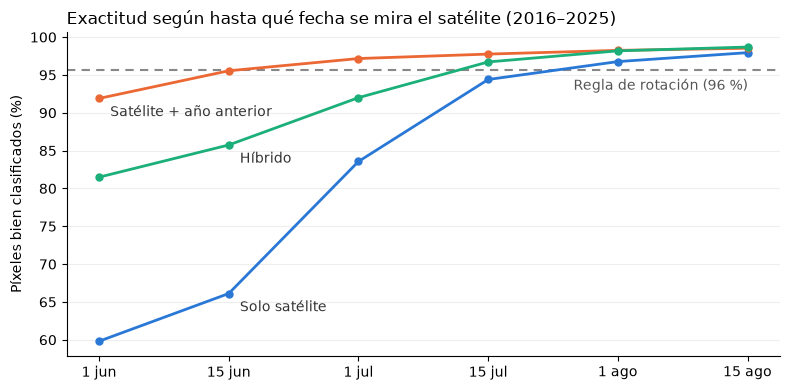

Por lote, satélite + año anterior le gana a la regla desde el 1 jul.
Por lote, híbrido le gana a la regla desde el 15 jul.


In [8]:
METODOS = {"regla": "Regla de rotación", "sat": "Solo satélite", "mix": "Satélite + año anterior", "hibrido": "Híbrido"}
COLOR_METODO = {"sat": "#2a78d6", "mix": "#eb6834", "hibrido": "#1baf7a"}   # la regla va en gris, como referencia


def por_lote(pred):
    """Una fila por lote, año y corte: verdad por mayoría de píxeles y probabilidad media de maíz."""
    return (pred.groupby(["fips", "id_lote", "anio", "corte"])
            .agg(y=("y", "mean"), regla=("regla", "mean"), prob_sat=("prob_sat", "mean"), prob_mix=("prob_mix", "mean"))
            .assign(y=lambda d: (d["y"] >= 0.5).astype(int)).reset_index())


def decidir_hibrido(tabla):
    """1 = maíz. Manda el satélite si está seguro; si no, la regla de rotación."""
    seguro = (tabla["prob_sat"] >= UMBRAL_SATELITE) | (tabla["prob_sat"] <= 1 - UMBRAL_SATELITE)
    return np.where(seguro, tabla["prob_sat"] >= 0.5, tabla["regla"] >= 0.5).astype(int)


def exactitud(tabla):
    return pd.Series({
        "regla": ((tabla["regla"] >= 0.5) == tabla["y"]).mean(),
        "sat": ((tabla["prob_sat"] >= 0.5) == tabla["y"]).mean(),
        "mix": ((tabla["prob_mix"] >= 0.5) == tabla["y"]).mean(),
        "hibrido": (decidir_hibrido(tabla) == tabla["y"]).mean(),
    })


if HAY_DATOS:
    lotes_pred = por_lote(predicciones)
    exact_px = predicciones.groupby("corte").apply(exactitud, include_groups=False)
    exact_lote = lotes_pred.groupby("corte").apply(exactitud, include_groups=False)
    resumen = pd.concat({"por píxel": exact_px, "por lote": exact_lote}, axis=1).rename(index=NOMBRE_CORTE)
    resumen.columns = [f"{nivel}: {METODOS[m]}" for nivel, m in resumen.columns]
    display((resumen * 100).round(1))

    fig, ax = plt.subplots(figsize=(8, 4))
    x = range(len(CORTES))
    regla_pct = exact_px["regla"].iloc[0] * 100
    ax.axhline(regla_pct, color="#888888", linewidth=1.5, linestyle=(0, (4, 3)))
    ax.annotate(f"Regla de rotación ({regla_pct:.0f} %)", (len(CORTES) - 1, regla_pct), xytext=(0, -14),
                textcoords="offset points", ha="right", color="#555555")
    for m in COLOR_METODO:
        ax.plot(x, exact_px[m].to_numpy() * 100, color=COLOR_METODO[m], linewidth=2, marker="o", markersize=5)
        # Etiquetas al principio, donde las líneas están separadas (al final se juntan)
        donde = 0 if m == "mix" else 1
        ax.annotate(METODOS[m], (donde, exact_px[m].iloc[donde] * 100), xytext=(8, -10),
                    textcoords="offset points", ha="left", va="center", color="#333333")
    ax.set_xticks(list(x), [NOMBRE_CORTE[c] for c in CORTES])
    ax.set_ylabel("Píxeles bien clasificados (%)")
    ax.set_title("Exactitud según hasta qué fecha se mira el satélite (2016–2025)", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#eeeeee")
    plt.tight_layout()
    plt.show()

    for m in ["mix", "hibrido"]:
        gana = exact_lote[m] > exact_lote["regla"]
        primero = next((c for c in CORTES if all(gana[d] for d in CORTES if d >= c)), None)
        print(f"Por lote, {METODOS[m].lower()} le gana a la regla desde el {NOMBRE_CORTE[primero]}." if primero
              else f"Por lote, {METODOS[m].lower()} no le gana a la regla de forma estable.")
    DESDE_SATELITE = next((c for c in CORTES if all(exact_lote.at[d, "hibrido"] > exact_lote.at[d, "regla"] for d in CORTES if d >= c)), None)
else:
    print("En espera de la entrega.")

## 8. Dónde falla la regla: los años en que el lote no rotó

La regla acierta casi siempre, así que el valor del satélite está en los pocos lote-años en que el productor **cambió el plan**: repitió el cultivo o volvió a rotar después de repetir. Ahí la regla se equivoca seguro.

La tabla muestra esos lote-años (2016–2025) y la probabilidad de maíz de cada modelo en cada fecha. Acá la verdad es siempre la contraria de la regla, así que el modelo acierta cuando su probabilidad cae del lado de la verdad (≥ 0,5 si fue maíz).

Es la comparación que decide el método: "satélite + año anterior" se queda pegado a la regla justo en estos casos, y "solo satélite" los ve.

In [9]:
if HAY_DATOS:
    rompio = lotes_pred[(lotes_pred["corte"] == CORTE_FRONT) & ((lotes_pred["regla"] >= 0.5) != lotes_pred["y"])][["id_lote", "anio"]]
    print(f"Lote-años en que la regla falla: {len(rompio)} de {lotes_pred.groupby(['id_lote', 'anio']).ngroups}")
    if len(rompio):
        casos = lotes_pred.merge(rompio, on=["id_lote", "anio"])
        for col, nombre in [("prob_mix", "Satélite + año anterior"), ("prob_sat", "Solo satélite")]:
            tabla_casos = casos.pivot_table(index=["id_lote", "anio", "y"], columns="corte", values=col).round(2)
            tabla_casos = tabla_casos.rename(columns=NOMBRE_CORTE).reset_index()
            tabla_casos["real"] = tabla_casos["y"].map({1: "maíz", 0: "soja"})
            print(f"\nProbabilidad de maíz, {nombre.lower()}:")
            display(tabla_casos.drop(columns="y"))
        al_corte = casos[casos["corte"] == CORTE_FRONT]
        print(f"\nAl {NOMBRE_CORTE[CORTE_FRONT]}, en los años en que la regla falla, aciertan: "
              f"satélite + año anterior {((al_corte['prob_mix'] >= 0.5) == al_corte['y']).mean():.0%}, "
              f"solo satélite {((al_corte['prob_sat'] >= 0.5) == al_corte['y']).mean():.0%}, "
              f"híbrido {(decidir_hibrido(al_corte) == al_corte['y']).mean():.0%}.")
else:
    print("En espera de la entrega.")

Lote-años en que la regla falla: 5 de 100

Probabilidad de maíz, satélite + año anterior:


corte,id_lote,anio,1 jun,15 jun,1 jul,15 jul,1 ago,15 ago,real
0,18157_181825001116483,2016,0.86,0.97,0.95,0.96,0.96,0.96,maíz
1,19047_191825002083543,2020,0.03,0.03,0.84,0.94,0.95,0.97,maíz
2,19047_191825002083543,2023,0.02,0.02,0.40,0.44,0.75,0.79,maíz
3,19165_191825002368896,2024,0.02,0.01,0.45,0.80,0.73,0.80,maíz
4,19165_191825002368896,2025,0.03,0.02,0.02,0.17,0.59,0.57,maíz



Probabilidad de maíz, solo satélite:


corte,id_lote,anio,1 jun,15 jun,1 jul,15 jul,1 ago,15 ago,real
0,18157_181825001116483,2016,0.91,0.98,0.99,0.99,0.99,0.98,maíz
1,19047_191825002083543,2020,0.30,0.54,0.98,0.98,0.98,0.99,maíz
2,19047_191825002083543,2023,0.10,0.25,0.90,0.87,0.96,0.95,maíz
3,19165_191825002368896,2024,0.11,0.13,0.69,0.87,0.84,0.90,maíz
4,19165_191825002368896,2025,0.30,0.28,0.67,0.88,0.98,0.98,maíz



Al 15 jul, en los años en que la regla falla, aciertan: satélite + año anterior 60%, solo satélite 100%, híbrido 100%.


## 9. Control: un lote que el modelo nunca vio

En el paso 6, el modelo se entrena con los años anteriores de **todos** los lotes, incluido el que después clasifica. Eso es realista (el CDL de los años anteriores de cualquier lote es público), pero con solo 10 lotes el modelo podría estar aprendiendo cómo se ve **ese** lote en particular.

Para descartarlo, en la fecha del front (`CORTE_FRONT`) se repite la validación **sacando además el lote de prueba** del entrenamiento. Si la exactitud se mantiene, el modelo sirve para un lote nuevo. Son 10 años × 10 lotes × 2 modelos = 200 entrenamientos (unos 4 minutos).

In [10]:
if HAY_DATOS:
    n_quincenas = CORTES[CORTE_FRONT]
    X_sat = armar_features(datos, n_quincenas, False)
    X_mix = armar_features(datos, n_quincenas, True)
    filas = []
    for anio in ANIOS_VALIDACION:
        for lote in datos["id_lote"].unique():
            entreno = (datos["anio"] < anio) & (datos["id_lote"] != lote)
            prueba = (datos["anio"] == anio) & (datos["id_lote"] == lote)
            if not prueba.any():
                continue
            p_sat = entrenar(X_sat[entreno], datos.loc[entreno, "y"]).predict_proba(X_sat[prueba])[:, 1]
            p_mix = entrenar(X_mix[entreno], datos.loc[entreno, "y"]).predict_proba(X_mix[prueba])[:, 1]
            filas.append(datos.loc[prueba, CLAVE + ["anio", "y", "regla"]].assign(corte=CORTE_FRONT, prob_sat=p_sat, prob_mix=p_mix))
    lote_nuevo = pd.concat(filas, ignore_index=True)

    comparar = pd.DataFrame({
        "lote visto (paso 6)": exactitud(lotes_pred[lotes_pred["corte"] == CORTE_FRONT]),
        "lote nuevo": exactitud(por_lote(lote_nuevo)),
    }).rename(index=METODOS)
    print(f"Exactitud por lote al {NOMBRE_CORTE[CORTE_FRONT]}, 2016–2025 (%):")
    display((comparar * 100).round(1))
else:
    print("En espera de la entrega.")

Exactitud por lote al 15 jul, 2016–2025 (%):


,lote visto (paso 6),lote nuevo
Regla de rotación,95.0,95.0
Solo satélite,96.0,96.0
Satélite + año anterior,97.0,95.0
Híbrido,99.0,99.0


## 10. La temporada de demo: qué se sabía en cada fecha

`ANIO_DEMO` hace de "temporada en curso". Sus predicciones ya salieron del paso 6: se entrenó solo con los años anteriores, y en cada corte se usaron solo las pasadas hasta esa fecha. El CDL de ese año no se usó para nada, salvo para comprobar al final.

Para cada lote: la probabilidad de maíz del satélite en cada fecha, lo que decía la regla, lo que decide el híbrido al `CORTE_FRONT` y lo que terminó diciendo el USDA.

In [11]:
if HAY_DATOS:
    demo = lotes_pred[lotes_pred["anio"] == ANIO_DEMO]
    a_texto = {1: "maíz", 0: "soja"}
    tabla_demo = demo.pivot_table(index="id_lote", columns="corte", values="prob_sat").round(2).rename(columns=NOMBRE_CORTE)
    tabla_demo["regla"] = (demo.groupby("id_lote")["regla"].first() >= 0.5).astype(int).map(a_texto)
    al_corte = demo[demo["corte"] == CORTE_FRONT].set_index("id_lote")
    tabla_demo[f"híbrido al {NOMBRE_CORTE[CORTE_FRONT]}"] = pd.Series(decidir_hibrido(al_corte), index=al_corte.index).map(a_texto)
    tabla_demo["CDL (USDA)"] = demo.groupby("id_lote")["y"].first().map(a_texto)
    print(f"Probabilidad de maíz por fecha según el satélite, temporada {ANIO_DEMO}:")
    display(tabla_demo)
else:
    print("En espera de la entrega.")

Probabilidad de maíz por fecha según el satélite, temporada 2025:


corte,1 jun,15 jun,1 jul,15 jul,1 ago,15 ago,regla,híbrido al 15 jul,CDL (USDA)
id_lote,,,,,,,,,
17019_171825005060041,0.85,0.74,0.79,1.00,1.00,1.00,maíz,maíz,maíz
17019_171825005511042,0.44,0.56,0.70,0.06,0.02,0.01,soja,soja,soja
18157_181825000203707,0.67,0.85,0.85,0.11,0.01,0.01,soja,soja,soja
18157_181825001116483,0.71,0.67,0.74,0.62,0.04,0.01,soja,soja,soja
19047_191825002083543,0.75,0.69,0.98,0.99,1.00,1.00,maíz,maíz,maíz
19079_191825000600003,0.45,0.10,0.01,0.01,0.00,0.00,soja,soja,soja
19079_191825001174693,0.23,0.09,0.02,0.01,0.01,0.01,soja,soja,soja
19079_191825002094751,0.24,0.30,0.03,0.01,0.00,0.00,soja,soja,soja
19165_191825001638480,0.47,0.24,0.11,0.05,0.02,0.02,soja,soja,soja


## 11. Guardar

| Archivo | Qué tiene | Para quién |
|---|---|---|
| `backend/Datos/cultivo_temporada_validacion.csv` | Exactitud por corte, año, nivel (píxel o lote) y método | `PUNTO6.md` y revisión |
| `backend/Datos/cultivo_temporada_lotes.csv` | Una fila por lote, año y corte: verdad del CDL, regla, probabilidad de maíz de cada modelo y decisión del híbrido | Revisión |
| `backend/Datos/cultivo_temporada_pixeles.csv` | La temporada de demo al `CORTE_FRONT`, por píxel: lat/lon, probabilidad de maíz del satélite y decisión del híbrido | Un mapa del lote, si el front lo quiere |
| `backend/Datos/front/cultivo_temporada.json` | Por lote, la temporada de demo fecha por fecha: qué cultivo, con qué método, probabilidad, confianza y frase en inglés | El front |

**Qué muestra el JSON en cada fecha:**

- **Antes de `DESDE_SATELITE`** (la primera fecha en que el híbrido le gana a la regla, por lote, y no vuelve a perder): la regla de rotación. Es demasiado temprano para el satélite.
- **Desde esa fecha:** el híbrido. Si el satélite está seguro, manda el satélite; si no, la regla.

**Confianza:**

- **high:** manda el satélite con 90 % o más;
- **medium:** manda el satélite con 80 a 90 %, o manda la regla (que acierta 95 % de las veces, pero falla justo cuando el productor cambia el plan);
- **low:** no hay pasadas suficientes. Hoy no pasa en los lotes de demo.

`experimentos.csv` no se toca: sus columnas son de regresión de rinde (MAE en bu/ac) y este punto es una clasificación. El registro de esta corrida es `cultivo_temporada_validacion.csv`.

In [12]:
if HAY_DATOS:
    validacion = []
    for nivel, tabla in [("pixel", predicciones), ("lote", lotes_pred)]:
        for (corte, anio), grupo in tabla.groupby(["corte", "anio"]):
            for metodo, valor in exactitud(grupo).items():
                validacion.append({"corte": corte, "anio": anio, "nivel": nivel, "metodo": metodo, "exactitud": round(valor, 4)})
    pd.DataFrame(validacion).to_csv(SALIDA / "cultivo_temporada_validacion.csv", index=False)
    lotes_pred["maiz_hibrido"] = decidir_hibrido(lotes_pred)
    lotes_pred.round({"regla": 3, "prob_sat": 3, "prob_mix": 3}).to_csv(SALIDA / "cultivo_temporada_lotes.csv", index=False)

    px_demo = predicciones[(predicciones["anio"] == ANIO_DEMO) & (predicciones["corte"] == CORTE_FRONT)].copy()
    px_demo["maiz_hibrido"] = decidir_hibrido(px_demo)
    px_demo = px_demo.merge(pixeles[CLAVE + ["lat", "lon"]], on=CLAVE)
    px_demo = px_demo[CLAVE + ["lat", "lon", "prob_sat", "maiz_hibrido", "y"]].rename(
        columns={"prob_sat": "prob_maiz_satelite", "y": "maiz_segun_cdl"})
    px_demo.round({"prob_maiz_satelite": 3}).to_csv(SALIDA / "cultivo_temporada_pixeles.csv", index=False)

    nombres = pd.read_csv(RUTA_CONDADOS, dtype={"fips": str}).set_index("fips") if RUTA_CONDADOS.exists() else pd.DataFrame()
    lotes_info = pd.read_csv(RUTA_LOTES / "lotes.csv", dtype=TIPOS).set_index("id_lote")
    exactitud_por_fecha = {c: {"rule": round(float(exact_lote.at[c, "regla"]), 3), "satellite": round(float(exact_lote.at[c, "sat"]), 3),
                               "satellite_plus_last_year": round(float(exact_lote.at[c, "mix"]), 3),
                               "hybrid": round(float(exact_lote.at[c, "hibrido"]), 3)} for c in CORTES}
    regla_pct = exact_lote["regla"].iloc[0]

    def leer_fecha(r):
        """Qué se muestra en una fecha: método, cultivo, probabilidad, confianza y frase."""
        p, corte = float(r["prob_sat"]), r["corte"]
        maiz_regla = r["regla"] >= 0.5
        seguro = max(p, 1 - p) >= UMBRAL_SATELITE
        usa_satelite = DESDE_SATELITE is not None and corte >= DESDE_SATELITE and seguro
        fecha_en = NOMBRE_CORTE_EN[corte]
        if usa_satelite:
            c = "maiz" if p >= 0.5 else "soja"
            prob = max(p, 1 - p)
            nivel = "high" if prob >= 0.9 else "medium"
            motivo = (f"Satellite passes so far point to {NOMBRE_EN[c]} ({prob:.0%}). On {fecha_en}, this method was right in "
                      f"{exact_lote.at[corte, 'hibrido']:.0%} of field-seasons 2016–2025.")
            cambio = " That's not the usual switch from last year's crop." if (c == "maiz") == (not maiz_regla) else ""
            texto = (f"As of {fecha_en}, this field looks like {NOMBRE_EN[c]} ({prob:.0%} likely), from Sentinel-2 and Landsat passes.{cambio} "
                     f"USDA's crop map for {ANIO_DEMO} comes out months later.")
            metodo = "satellite"
        else:
            c = "maiz" if maiz_regla else "soja"
            prob = None
            nivel = "medium"
            temprano = DESDE_SATELITE is None or corte < DESDE_SATELITE
            motivo = (("Too early for the satellite. " if temprano else "The satellite isn't sure yet. ")
                      + f"Going by last year's crop, which was right in {regla_pct:.0%} of field-seasons 2016–2025.")
            texto = (f"As of {fecha_en}, this field is probably {NOMBRE_EN[c]}, going by last year's crop. "
                     + ("It's too early to see it from space." if temprano else "Satellite passes don't show it clearly yet."))
            metodo = "rotation_rule"
        return {"date": f"{ANIO_DEMO}-{corte}", "method": metodo, "crop": CULTIVO_EN[c],
                "prob": None if prob is None else round(prob, 3), "satellite_prob_corn": round(p, 3),
                "confidence": {"level": nivel, "reason": motivo}, "text": texto}

    campos = {}
    for lote, grupo in lotes_pred[lotes_pred["anio"] == ANIO_DEMO].groupby("id_lote"):
        fips = grupo["fips"].iloc[0]
        campos[lote] = {
            "fips": fips, "county": nombres["condado"].get(fips) if len(nombres) else None,
            "centroid": [round(float(lotes_info.at[lote, "lon_centroide"]), 5), round(float(lotes_info.at[lote, "lat_centroide"]), 5)],
            "season": ANIO_DEMO,
            "rule_guess": CULTIVO_EN["maiz" if grupo["regla"].iloc[0] >= 0.5 else "soja"],
            "usda_cdl": CULTIVO_EN["maiz" if grupo["y"].iloc[0] == 1 else "soja"],
            "as_of": [leer_fecha(r) for _, r in grupo.sort_values("corte").iterrows()],
        }

    documento = {
        "version_contrato": "0.2", "generado": datetime.now().isoformat(timespec="seconds"),
        "es_prueba": False, "prototype": False, "source": "NASA/USGS Landsat · ESA Sentinel-2 (NASA HLS) · USDA CDL",
        "note": ("In-season crop guess for the demo fields, before USDA's Cropland Data Layer is published. Trained only on past "
                 f"years. Until {NOMBRE_CORTE_EN.get(DESDE_SATELITE, 'the satellite beats it')}, the guess is last year's rotation; "
                 "from then on, the satellite overrides it when it is at least "
                 f"{UMBRAL_SATELITE:.0%} sure. usda_cdl is the published answer, kept to check the guess; it was not used to make it."),
        "satellite_from": None if DESDE_SATELITE is None else f"{ANIO_DEMO}-{DESDE_SATELITE}",
        "accuracy_by_date": exactitud_por_fecha,
        "fields": campos,
    }
    (SALIDA / "front").mkdir(exist_ok=True)
    with open(SALIDA / "front" / "cultivo_temporada.json", "w", encoding="utf-8") as f:
        json.dump(documento, f, ensure_ascii=False, indent=1)
    print(f"El satélite entra desde el {NOMBRE_CORTE.get(DESDE_SATELITE)}.")
    print(f"Guardados cultivo_temporada_validacion.csv, cultivo_temporada_lotes.csv ({len(lotes_pred)} filas), "
          f"cultivo_temporada_pixeles.csv ({len(px_demo)} píxeles) y front/cultivo_temporada.json ({len(campos)} lotes)")
else:
    print("En espera de la entrega.")

El satélite entra desde el 15 jul.
Guardados cultivo_temporada_validacion.csv, cultivo_temporada_lotes.csv (600 filas), cultivo_temporada_pixeles.csv (5324 píxeles) y front/cultivo_temporada.json (10 lotes)


## Próximos pasos

- [ ] Acordar con el front dónde se muestra: la app trabaja por condado y esto es por lote. Una opción es la historia del condado ("this season, before USDA's map") o la pantalla del lote del punto 1.
- [ ] Para hacerlo por condado entero hacen falta las pasadas de Sentinel-2 de todo el condado, no solo de los 10 lotes de demo: pedirlo al pipeline (`docs/ml/pedidos_datos.md`).
- [ ] El umbral del híbrido (0,8) se eligió mirando los años de prueba: confirmarlo con una temporada nueva (2026) antes de dar la exactitud como firme.
- [ ] Sumar columnas de clasificación (exactitud) a `experimentos.csv`, o acordar un registro aparte, con el equipo.
- [ ] Probar con más clases (trigo, alfalfa) cuando haya lotes con esos cultivos. Hoy son píxeles sueltos.